# KOMBINIRANI MODEL: LSTM + XGBOOST + RIDGE

### Priprema modela i podataka

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

#Učitaj podatke
df = pd.read_csv("output/spojeni_podaci.csv")
features = ["insolacija", "naoblaka", "temperatura", "Peak Power (kW)"]
target = "PV Yield (kWh)"
df = df[features + [target]].dropna()

#Dodaj rolling prosjeke (vremenska dinamika)
for col in ["insolacija", "temperatura", "naoblaka"]:
    df[f"{col}_roll_mean_7"] = df[col].rolling(window=7, min_periods=1).mean()
    df[f"{col}_roll_std_7"] = df[col].rolling(window=7, min_periods=1).std()

df = df.dropna()

#Skaliranje
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_all = df.drop(columns=[target])
y_all = df[[target]]

X_scaled = scaler_X.fit_transform(X_all)
y_scaled = scaler_y.fit_transform(y_all).flatten()

#LSTM priprema
def create_sequences(X, y, seq_length=20):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i+seq_length])
        y_seq.append(y[i+seq_length])
    return np.array(X_seq), np.array(y_seq)

X_seq, y_seq = create_sequences(X_scaled, y_scaled)
X_seq_tensor = torch.tensor(X_seq, dtype=torch.float32)
y_seq_tensor = torch.tensor(y_seq, dtype=torch.float32).view(-1, 1)

split_idx = int(0.8 * len(X_seq))
X_train_seq, X_test_seq = X_seq_tensor[:split_idx], X_seq_tensor[split_idx:]
y_train_seq, y_test_seq = y_seq_tensor[:split_idx], y_seq_tensor[split_idx:]

train_ds = TensorDataset(X_train_seq, y_train_seq)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)

### Inicijalizacija  i predikcija LSTM modela

In [2]:
#LSTM model
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=2):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

model = LSTMModel(input_size=X_train_seq.shape[2])
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

for epoch in range(50):
    model.train()
    for X_batch, y_batch in train_dl:
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        loss.backward()
        optimizer.step()

#LSTM predikcija
model.eval()
with torch.no_grad():
    y_pred_lstm = model(X_test_seq).numpy()
    y_pred_lstm_inv = scaler_y.inverse_transform(y_pred_lstm)
    y_test_inv = scaler_y.inverse_transform(y_test_seq.numpy())


### Inicijalizacija XGBoost modela i Ridge meta-modela

In [3]:
#XGBoost model
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_all.values.ravel(), test_size=0.2, random_state=42)
xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

#Ensemble - Ridge meta-model
min_len = min(len(y_pred_lstm_inv), len(y_pred_xgb))
meta_input = np.vstack((y_pred_lstm_inv[:min_len].flatten(), y_pred_xgb[:min_len])).T
meta_target = y_test_inv[:min_len]

meta_model = Ridge(alpha=1.0)
meta_model.fit(meta_input, meta_target)
meta_pred = meta_model.predict(meta_input)

### Evaluacija modela

In [4]:
#Evaluacija
mae = mean_absolute_error(meta_target, meta_pred)
mse = mean_squared_error(meta_target, meta_pred)
r2 = r2_score(meta_target, meta_pred)

print("Evaluacija kombiniranog modela (LSTM + XGBoost + Ridge):")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R²: {r2:.2f}")


Evaluacija kombiniranog modela (LSTM + XGBoost + Ridge):
MAE: 4.38
MSE: 29.02
R²: 0.54


### Vizualizacija

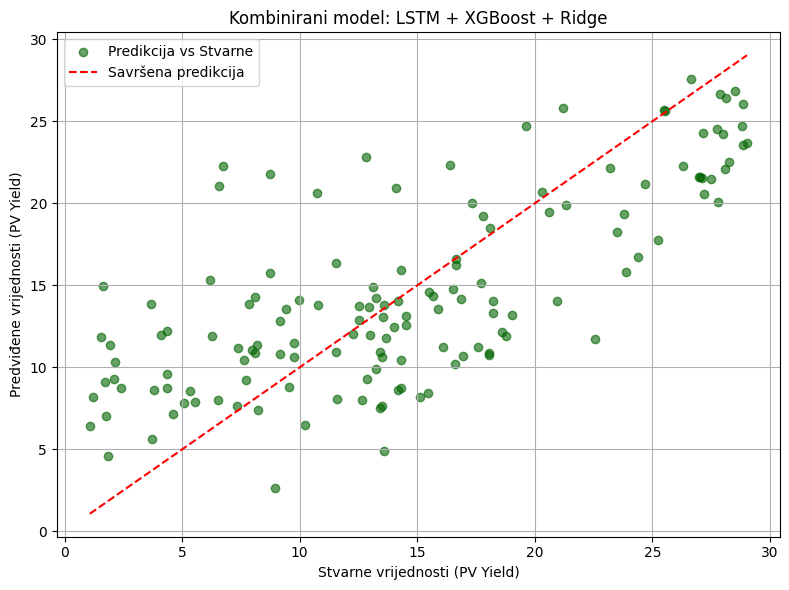

In [6]:
#Vizualizacija
plt.figure(figsize=(8, 6))
plt.scatter(meta_target, meta_pred, color='darkgreen', alpha=0.6, label='Predikcija vs Stvarne')
lims = [min(meta_target.min(), meta_pred.min()), max(meta_target.max(), meta_pred.max())]
plt.plot(lims, lims, 'r--', label='Savršena predikcija')
plt.xlabel("Stvarne vrijednosti (PV Yield)")
plt.ylabel("Predviđene vrijednosti (PV Yield)")
plt.title("Kombinirani model: LSTM + XGBoost + Ridge")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("grafovi/LSTMXGBoost.png")
plt.show()